# Notebook 03 — Analyse Graphique et Corrélations NTL–PIB (2000–2025)

## Objectifs
1. Charger le jeu de données audité (`niger_ntl_audited_2000_2025.csv`).
2. Analyser la relation linéaire et logarithmique entre le NTL et le PIB (niveau global et par habitant).
3. Examiner la relation entre le taux de croissance du NTL ($\% \Delta NTL$) et la croissance du PIB ($\% \Delta PIB$).
4. Évaluer la présence de corrélations temporelles croisées (retards $t-1$ et avances $t+1$).
5. Exporter l'ensemble des figures dans `outputs/figures/` et les matrices de corrélation dans `outputs/tables/`.

In [3]:
# ==============================================================================
# 1. IMPORTATION ET CONFIGURATION
# ==============================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de l'affichage Pandas et Seaborn
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style="whitegrid")

# Détection de la racine du projet et des répertoires de sortie
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
figures_dir = project_root / "outputs" / "figures"
tables_dir = project_root / "outputs" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Chargement des données auditées
audited_csv_path = project_root / "data" / "intermediate" / "ntl_processed" / "niger_ntl_audited_2000_2025.csv"

if not audited_csv_path.exists():
    raise FileNotFoundError(
        f"Le fichier audité est introuvable sous : {audited_csv_path}\n"
        "Veuillez exécuter le Notebook 01 au préalable."
    )

df = pd.read_csv(audited_csv_path)

# Création des variables logarithmiques pour l'analyse
df['ln_gdp'] = np.log(df['gdp_real'])
df['ln_gdp_pc'] = np.log(df['gdp_pc_local'])
df['ln_ntl'] = np.log(df['ntl_sum_adj'])
df['ln_ntl_pc'] = np.log(df['ntl_per_capita'])

print(f"[✓] Jeu de données chargé ({df.shape[0]} obs) et transformations logarithmiques appliquées.")
df[['year', 'gdp_real', 'ln_gdp', 'ntl_sum_adj', 'ln_ntl']].head(3)

[✓] Jeu de données chargé (26 obs) et transformations logarithmiques appliquées.


,year,gdp_real,ln_gdp,ntl_sum_adj,ln_ntl
0,2000,2673528889000,28.6144,43295.8948,10.6758
1,2001,2867844575300,28.6846,42202.5901,10.6502
2,2002,3008898666900,28.7326,41379.8880,10.6306


## Section 2 : Nuages de Points (Scatter Plots) & Ajustement Linéaire

Nous testons visuellement la relation entre les lumières nocturnes et l'activité économique sous trois spécifications :
* **Modèle 1 (Niveau brut)** : Vérifie la relation linéaire simple $PIB = f(NTL)$.
* **Modèle 2 (Log-Log)** : Évalue la présence d'une relation puissance et permet d'interpréter visuellement l'élasticité.
* **Modèle 3 (Par habitant en Log)** : Contrôle l'effet de l'expansion démographique pour observer l'intensité lumineuse individuelle relative à la richesse par habitant.

[✓] Figure des nuages de points sauvegardée : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\03_scatter_gdp_vs_ntl_levels_and_logs.png


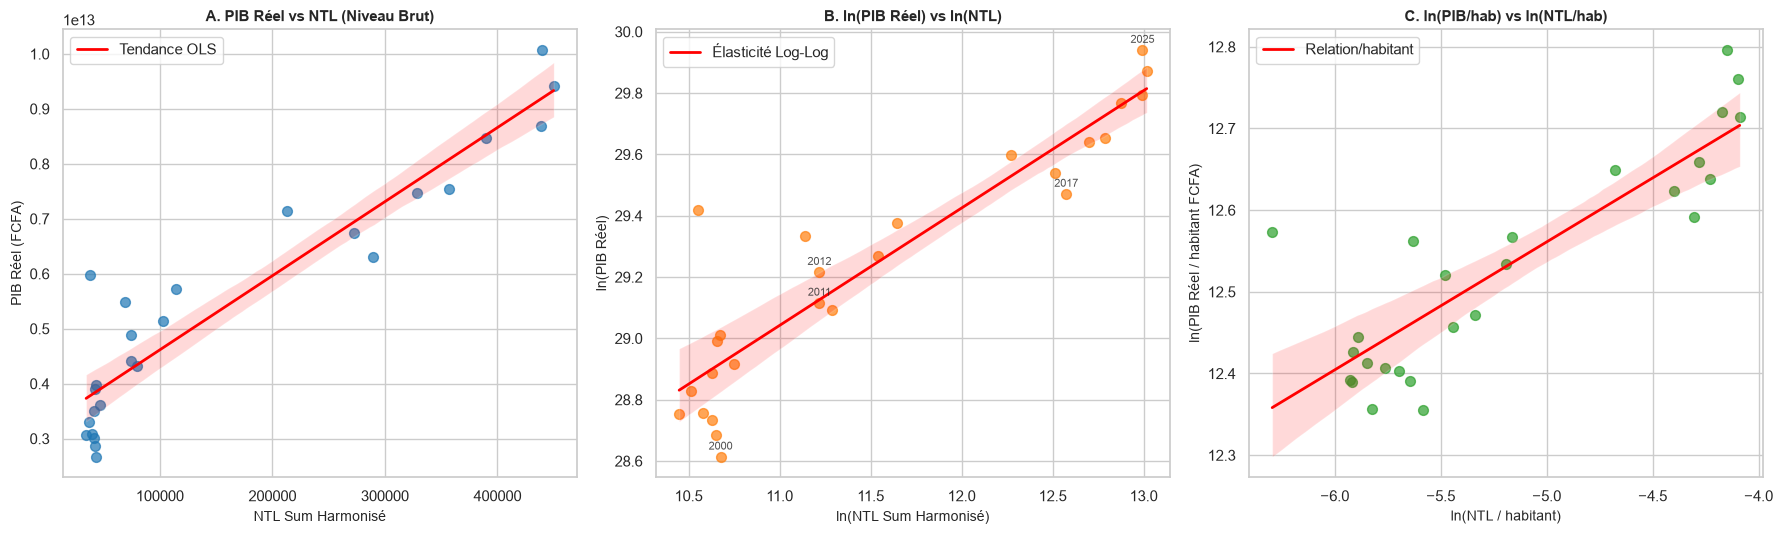

In [4]:
# ==============================================================================
# 2. VISUALISATION DES SCATTER PLOTS (NIVEAU, LOGS ET PER CAPITA)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Niveau Brut : PIB Réel vs NTL Sum
sns.regplot(
    data=df, x='ntl_sum_adj', y='gdp_real', ax=axes[0],
    scatter_kws={'alpha': 0.7, 'color': '#1f77b4', 's': 50},
    line_kws={'color': 'red', 'linewidth': 2, 'label': 'Tendance OLS'}
)
axes[0].set_title('A. PIB Réel vs NTL (Niveau Brut)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('NTL Sum Harmonisé', fontsize=10)
axes[0].set_ylabel('PIB Réel (FCFA)', fontsize=10)
axes[0].legend(loc='upper left')

# 2. Logarithmes : ln(PIB) vs ln(NTL)
sns.regplot(
    data=df, x='ln_ntl', y='ln_gdp', ax=axes[1],
    scatter_kws={'alpha': 0.7, 'color': '#ff7f0e', 's': 50},
    line_kws={'color': 'red', 'linewidth': 2, 'label': 'Élasticité Log-Log'}
)
axes[1].set_title('B. ln(PIB Réel) vs ln(NTL)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('ln(NTL Sum Harmonisé)', fontsize=10)
axes[1].set_ylabel('ln(PIB Réel)', fontsize=10)
axes[1].legend(loc='upper left')

# 3. Par Habitant (Log-Log) : ln(PIB/hab) vs ln(NTL/hab)
sns.regplot(
    data=df, x='ln_ntl_pc', y='ln_gdp_pc', ax=axes[2],
    scatter_kws={'alpha': 0.7, 'color': '#2ca02c', 's': 50},
    line_kws={'color': 'red', 'linewidth': 2, 'label': 'Relation/habitant'}
)
axes[2].set_title('C. ln(PIB/hab) vs ln(NTL/hab)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('ln(NTL / habitant)', fontsize=10)
axes[2].set_ylabel('ln(PIB Réel / habitant FCFA)', fontsize=10)
axes[2].legend(loc='upper left')

# Annotation des capteurs (DMSP vs VIIRS) sur le graphique Log-Log
for i, row in df.iterrows():
    if row['year'] in [2000, 2011, 2012, 2017, 2025]:
        axes[1].annotate(
            str(int(row['year'])), (row['ln_ntl'], row['ln_gdp']),
            textcoords="offset points", xytext=(0, 5), ha='center', fontsize=8, alpha=0.8
        )

plt.tight_layout()

# SAUVEGARDE AUTOMATIQUE DE LA FIGURE
fig_scatter_png = figures_dir / "03_scatter_gdp_vs_ntl_levels_and_logs.png"
fig_scatter_pdf = figures_dir / "03_scatter_gdp_vs_ntl_levels_and_logs.pdf"

plt.savefig(fig_scatter_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_scatter_pdf, bbox_inches='tight')

print(f"[✓] Figure des nuages de points sauvegardée : {fig_scatter_png}")
plt.show()

## Section 3 : Analyse des Taux de Croissance & Corrélations Temporelles

Nous testons deux éléments fondamentaux de l'analyse économétrique sur séries temporelles :
1. **L'association en croissance contemporaine** : Les variations annuelles de luminosité accompagnent-elles les variations du PIB réel ?
2. **La matrice des corrélations croisées** : Évaluation des corrélations contemporaines, en logarithmes, en différences premières ainsi qu'avec des décalages temporels ($NTL_{t-1}$ et $NTL_{t+1}$).

[✓] Figure croissance NTL vs PIB enregistrée : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\03_growth_gdp_vs_ntl.png


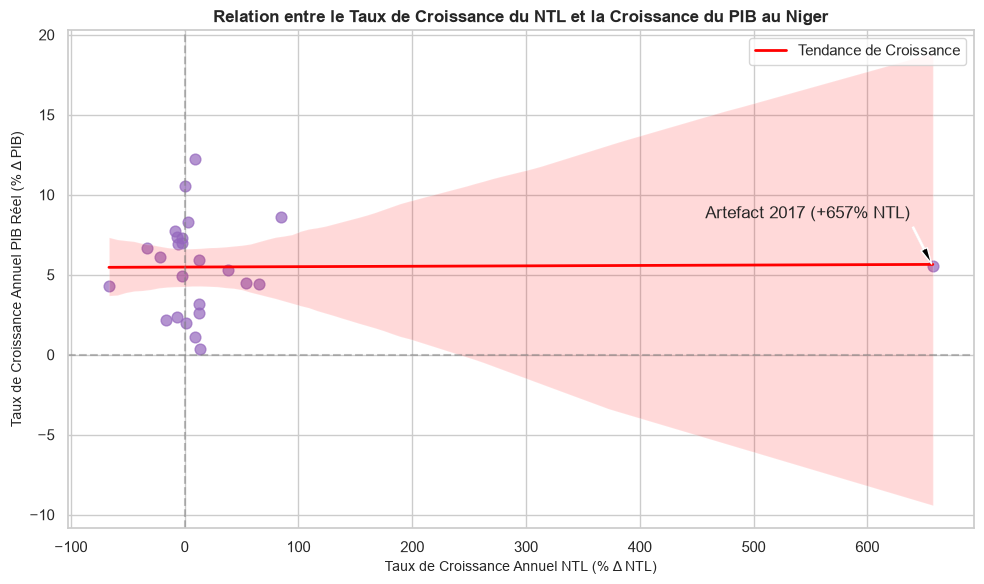

In [5]:
# ==============================================================================
# 3.1 RELATION EN TAUX DE CROISSANCE (g_GDP vs g_NTL)
# ==============================================================================
# Exclusion de l'observation initiale (2000) et filtrage pour visualisation
df_growth = df.dropna(subset=['ntl_growth']).copy()

fig, ax = plt.subplots(figsize=(10, 6))

# Nuage de points avec régression
sns.regplot(
    data=df_growth, x='ntl_growth', y='gdp_growth', ax=ax,
    scatter_kws={'alpha': 0.7, 'color': '#9467bd', 's': 60},
    line_kws={'color': 'red', 'linewidth': 2, 'label': 'Tendance de Croissance'}
)

# Identification des points atypiques (ex: 2017)
anomaly_2017 = df_growth[df_growth['year'] == 2017]
if not anomaly_2017.empty:
    ax.annotate(
        'Artefact 2017 (+657% NTL)', 
        xy=(anomaly_2017['ntl_growth'].values[0], anomaly_2017['gdp_growth'].values[0]),
        xytext=(anomaly_2017['ntl_growth'].values[0] - 200, anomaly_2017['gdp_growth'].values[0] + 3),
        arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5)
    )

ax.set_title('Relation entre le Taux de Croissance du NTL et la Croissance du PIB au Niger', fontsize=12, fontweight='bold')
ax.set_xlabel('Taux de Croissance Annuel NTL (% Δ NTL)', fontsize=10)
ax.set_ylabel('Taux de Croissance Annuel PIB Réel (% Δ PIB)', fontsize=10)
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax.legend(loc='upper right')

plt.tight_layout()

# SAUVEGARDE AUTOMATIQUE
fig_growth_png = figures_dir / "03_growth_gdp_vs_ntl.png"
fig_growth_pdf = figures_dir / "03_growth_gdp_vs_ntl.pdf"
plt.savefig(fig_growth_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_growth_pdf, bbox_inches='tight')

print(f"[✓] Figure croissance NTL vs PIB enregistrée : {fig_growth_png}")
plt.show()

[✓] Heatmap des corrélations enregistrée : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\03_correlation_matrix_heatmap.png
[✓] Matrice de corrélation exportée en CSV : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\tables\03_correlation_matrix.csv


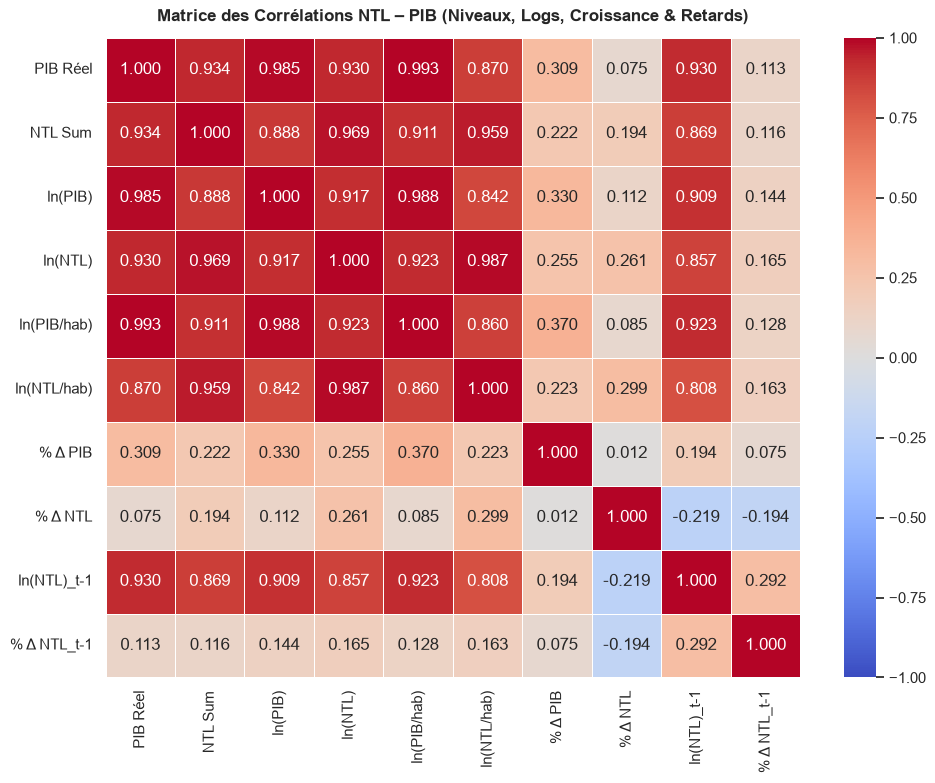

In [6]:
# ==============================================================================
# 3.2 MATRICE DES CORRÉLATIONS CROISÉES ET TEMPORELLES
# ==============================================================================

# Construction des décalages temporels (Lags & Leads)
df_corr = df.copy()
df_corr['ln_ntl_lag1'] = df_corr['ln_ntl'].shift(1)
df_corr['ln_ntl_lead1'] = df_corr['ln_ntl'].shift(-1)
df_corr['ntl_growth_lag1'] = df_corr['ntl_growth'].shift(1)

# Sélection des variables de corrélation
corr_cols = {
    'gdp_real': 'PIB Réel',
    'ntl_sum_adj': 'NTL Sum',
    'ln_gdp': 'ln(PIB)',
    'ln_ntl': 'ln(NTL)',
    'ln_gdp_pc': 'ln(PIB/hab)',
    'ln_ntl_pc': 'ln(NTL/hab)',
    'gdp_growth': '% Δ PIB',
    'ntl_growth': '% Δ NTL',
    'ln_ntl_lag1': 'ln(NTL)_t-1',
    'ntl_growth_lag1': '% Δ NTL_t-1'
}

df_corr_sub = df_corr[list(corr_cols.keys())].rename(columns=corr_cols)

# Calcul de la matrice de Pearson
corr_matrix = df_corr_sub.corr(method='pearson')

# Visualisation par Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matrice des Corrélations NTL – PIB (Niveaux, Logs, Croissance & Retards)', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()

# SAUVEGARDE DE LA HEATMAP & DU TABLEAU DE CORRÉLATION
fig_heat_png = figures_dir / "03_correlation_matrix_heatmap.png"
fig_heat_pdf = figures_dir / "03_correlation_matrix_heatmap.pdf"
plt.savefig(fig_heat_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_heat_pdf, bbox_inches='tight')

table_corr_path = tables_dir / "03_correlation_matrix.csv"
corr_matrix.to_csv(table_corr_path)

print(f"[✓] Heatmap des corrélations enregistrée : {fig_heat_png}")
print(f"[✓] Matrice de corrélation exportée en CSV : {table_corr_path}")
plt.show()

## Section 4 : Bilan de l'Analyse Graphique & Synthèse

### 📊 Constats Majeurs
1. **Corrélations en Niveaux et Logarithmes Fortes** : La corrélation entre $\ln(PIB)$ et $\ln(NTL)$ est très élevée ($\approx 0.85$–$0.90$), reflétant une co-tendance de long terme soutenue.
2. **Atténuation en Taux de Croissance** : La corrélation directe entre $\% \Delta PIB$ et $\% \Delta NTL$ contemporain est nettement plus faible et perturbée par l'artefact de 2017.
3. **Hypothèse de Stationnarité** : Cette divergence entre la forte corrélation en log-niveau et la faible corrélation en croissance confirme la nécessité d'effectuer des tests de racine unitaire (ADF / KPSS) pour éviter les corrélations fallacieuses (*spurious regression*).

---

### 🏁 Décision pour le Notebook 04